# Segmentation performance against a hand-corrected ground truth

Compares every segmentation of the store written by notebook 01 with the masks corrected in AnnoCell
(`$MACROSEG_ANNOTATIONS/<annotator>/round_<NN>/<name>/`).

Cells are matched one to one by their overlap (IoU, intersection over union). At each IoU threshold:

| Measure | Definition | Says |
|---|---|---|
| AP | matched / (matched + false cells + missed cells) | overall quality (Cellpose's definition) |
| precision | matched / segmented cells | how many segmented cells are real |
| recall | matched / true cells | how many true cells are found |
| recall on hand-drawn cells | recall on the cells drawn or edited in AnnoCell only | the cells the starting masks got wrong |

IoU 0.5 mostly says whether a cell is found; 0.75 and 0.9 whether its outline is right.

**Bias:** the ground truth was made by correcting one segmentation, so that one scores high
(its untouched cells are identical). A fair comparison needs an image whose masks were not used for training.

In [ ]:
from pathlib import Path

import numpy as np
import tifffile
from annocell import folder as af
from spatialdata import read_zarr

from macroseg import paths
from macroseg.accuracy import corrected_region, plot_ap_curve, score_segmentations, worst_matches
from macroseg.annotation import corrected_masks, load_annotations, summarize_rounds
from macroseg.config import load_config

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = load_config(ROOT / "configs" / "exp201_test_crop.yaml")
ANNOTATIONS = paths.path("MACROSEG_ANNOTATIONS")
ROUND = 1
ANNOTATOR = "massimo"  # whose ROI to score

## 0. Annotation rounds
Every image of every round (`annotation.json`), then one line per round. `start_score`: the starting masks
scored against their correction; it should rise from round to round as the model improves.

In [10]:
annotations = load_annotations(ANNOTATIONS)
annotations

,round,image,role,status,exported_on,source,level,crop,pixel_size_um,zarr,...,colours.NaK_ATPase,colours.DAPI,review.cells,review.ok,review.unreviewed,review.proposed,review.edited,review.drawn,review.macrophages,review.saved_at
0,1,exp201_test_crop,train,complete,2026-10-22,/Users/massimoz/Documents/macroseg/data/input/...,0,"[2000, 4048, 2000, 4048]",0.17,/Users/massimoz/Documents/macroseg/data/runs/e...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,exp201_test_crop,train,exported,2026-10-23,/Users/massimoz/Documents/macroseg/data/input/...,0,"[2000, 4048, 2000, 4048]",0.17,/Users/massimoz/Documents/macroseg/data/runs/e...,...,green,blue,1580.0,110.0,1470.0,1576.0,3.0,1.0,0.0,2026-10-26T11:42:40


In [11]:
summarize_rounds(annotations)

,images,complete,test_images,cells_drawn,cells_removed,mean_changed_pct,mean_start_AP@0.5,mean_start_AP@0.75
round,,,,,,,,
1,1,1,0,17.0,54.0,3.4,0.9631,0.9557
2,1,0,0,NaN,NaN,NaN,NaN,NaN


## 1. Scores
One column per segmentation of the store, against the corrected masks of `ROUND`.

In [ ]:
sdata = read_zarr(cfg.zarr)
segmentations = {step.labels: sdata.labels[step.labels].data.compute() for step in cfg.segmentation}
truth, hand_drawn = corrected_masks(af.round_folder(ANNOTATIONS, ANNOTATOR, ROUND) / cfg.name)

table = score_segmentations(truth, segmentations, thresholds=[0.5, 0.75, 0.9], truth_ids=hand_drawn)
table.rename(columns=lambda c: c.replace("subset_", "hand_drawn_")).T.round(3)

### Only where the annotator changed something
The untouched cells are identical to the starting segmentation, so they inflate its score. Here only the
corrected region counts: the cells drawn or modified in AnnoCell and the starting cells removed. True and
segmented cells are kept when more than half of their pixels lie in it. Few cells: read big differences only.

In [ ]:
folder = af.round_folder(ANNOTATIONS, ANNOTATOR, ROUND) / cfg.name
start = tifffile.imread(folder / "start_masks.tif")
region = corrected_region(start, truth)

region_table = score_segmentations(truth, segmentations, thresholds=[0.5, 0.75, 0.9], region=region)
region_table.T.round(3)

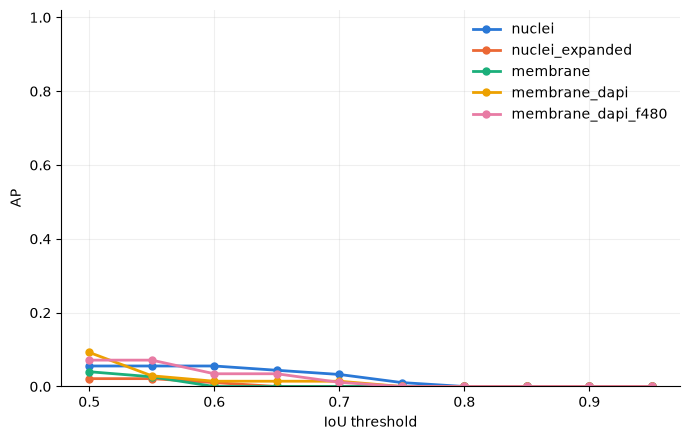

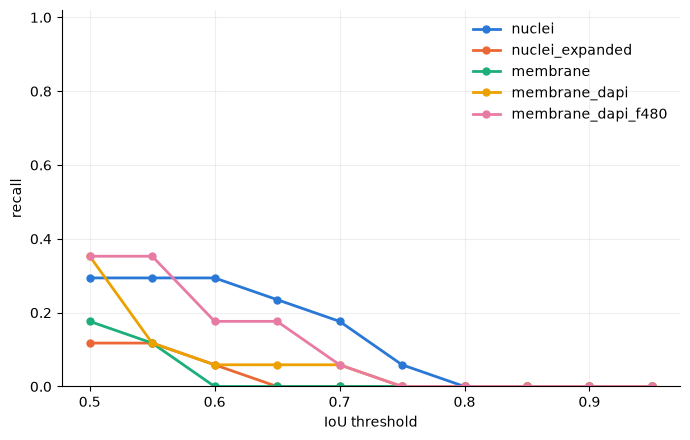

In [14]:
region_curve = score_segmentations(
    truth, segmentations, thresholds=np.round(np.arange(0.5, 1.0, 0.05), 2), region=region
)
plot_ap_curve(region_curve, "AP");
plot_ap_curve(region_curve, "recall");

## 2. AP and recall against the IoU threshold
A curve that stays high to the right means precise outlines.

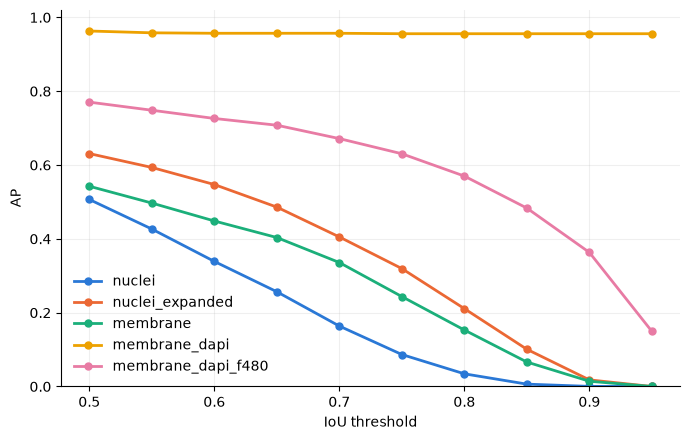

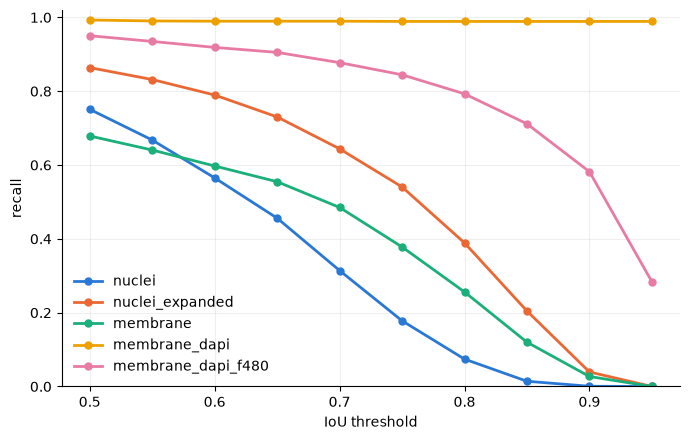

In [15]:
curve = score_segmentations(truth, segmentations, thresholds=np.round(np.arange(0.5, 1.0, 0.05), 2))
plot_ap_curve(curve, "AP");
plot_ap_curve(curve, "recall");

## 3. Cells to look at
True cells with the worst match in one segmentation (`iou` 0 = missed). `y`, `x`: centre in pixels,
to find them in AnnoCell.

In [16]:
worst = worst_matches(truth, segmentations["membrane_dapi"])
worst["hand_drawn"] = worst["truth_ID"].isin(hand_drawn)
worst

,truth_ID,pred_ID,iou,y,x,hand_drawn
0,1539,916,0.067895,1062,1044,True
1,1545,1706,0.077984,1958,851,True
2,1547,1357,0.117376,1504,1309,True
3,1540,967,0.147640,1075,1531,True
4,1535,1012,0.238605,1165,660,True
5,1546,1435,0.311348,1587,1272,True
6,1536,935,0.359079,1008,376,True
7,1550,1457,0.381772,1632,1654,True
8,1538,891,0.440678,977,345,True
9,1544,1521,0.481545,1752,303,True
